# Auditoría Ground Truth y Liga de Extractores SEC Form 8-K
## Comparativa RegEx vs. spaCy (Ventanas 0, ±1, ±2)
**Máster en Data Science — Trabajo de Fin de Máster (TFM)**
*Auditoría de 150 Eventos Regulatorios de la SEC (2010–2023) frente a Inferencia Real con FinBERT*

---
### Objetivos del Cuaderno
1. **Auditar el Ground Truth pericial** sobre 150 hechos relevantes 8-K estratificados entre los Big 6 bancos de Wall Street (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`).
2. **Calcular la Tabla de Posiciones Oficial de la Liga**: Comparación exhaustiva de las 6 variantes bajo métricas de Accuracy, Recall desglosado por clase (Positivo, Negativo, Neutro), Inversiones Graves (pos $\leftrightarrow$ neg) y Eficiencia de Tokens.
3. **Analizar Matrices de Confusión** en cuadrícula $2 \times 3$ para aislar patrones de sesgo y absorción neutra.
4. **Comparativas Head-to-Head (1 contra 1)**:
   - RegEx vs. spaCy bajo idéntico tamaño de ventana (V0 vs S0, V1 vs S1B, V2 vs S2B).
   - Impacto del tamaño de ventana contextual en documentos monocorporativos (Ventana 0 vs Ventana 1 vs Ventana 2).
5. **Generar el Dashboard Ejecutivo Visual (4 Paneles)** para la defensa y memoria del TFM.
6. **Determinar formalmente los 2 mejores extractores** para alimentar la fase de producción analítica de la SEC.


In [7]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from IPython.display import display

# Configuración visual profesional
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

# Resolver rutas
curr = Path.cwd().resolve()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
csv_audit = PROJ_ROOT / "scratch" / "finbert_sec_audit_150.csv"

df = pd.read_csv(csv_audit)
print(f"[OK] Dataset de auditoría cargado: {len(df)} eventos | {len(df.columns)} columnas")
print(f"Ruta: {csv_audit}")


[OK] Dataset de auditoría cargado: 150 eventos | 64 columnas
Ruta: C:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\scratch\finbert_sec_audit_150.csv


## 1. Distribución del Ground Truth Pericial en Hechos Relevantes SEC
Analizamos la composición del Ground Truth asignado por el auditor financiero pericial a lo largo de los diferentes tipos de ítems regulatorios y entidades bancarias.


In [8]:
print("Distribución Global de Polaridad Ground Truth:")
print(df["gt_sentiment_str"].value_counts())

# Matriz cruzada: Ítem regulatorio vs Polaridad Ground Truth
crosstab_item = pd.crosstab(df["item"], df["gt_sentiment_str"], margins=True)
display(crosstab_item)

# Matriz cruzada: Banco vs Polaridad Ground Truth
crosstab_bank = pd.crosstab(df["ticker"], df["gt_sentiment_str"], margins=True)
display(crosstab_bank)


Distribución Global de Polaridad Ground Truth:
gt_sentiment_str
NEUTRAL     134
NEGATIVE      9
POSITIVE      7
Name: count, dtype: int64


gt_sentiment_str,NEGATIVE,NEUTRAL,POSITIVE,All
item,,,,
Item 2.02,3,42,5,50
Item 5.02,0,25,0,25
Item 7.01,1,19,0,20
Item 8.01,4,34,2,40
Item 9.01,1,14,0,15
All,9,134,7,150


gt_sentiment_str,NEGATIVE,NEUTRAL,POSITIVE,All
ticker,,,,
BAC,1,21,1,23
C,1,19,0,20
GS,1,14,0,15
JPM,5,29,6,40
MS,0,13,0,13
WFC,1,38,0,39
All,9,134,7,150


## 2. Tabla Oficial de Posiciones de la Liga (Leaderboard Multiobjetivo)
Calculamos la clasificación de la Liga ponderando:
- **Accuracy Global (40%)**: Porcentaje de concordancia exacta con el Ground Truth.
- **F1-Macro / Recall Equilibrado (25%)**: Media armónica del recall en clases positiva, negativa y neutra.
- **Eficiencia de Tokens (20%)**: Penalización de sobrecoste por secuencias redundantes $>256$ tokens.
- **Seguridad Analítica (15%)**: Penalización estricta de Inversiones Graves (predecir positivo ante evento negativo o viceversa).


In [9]:
variantes = ["RE_V0_PODA", "RE_V1_PODA", "RE_V2_PODA", "SPACY_S0", "SPACY_S1B", "SPACY_S2B"]
y_true = df["gt_sentiment"].astype(int)

filas_liga = []
for v in variantes:
    y_pred = df[f"{v}_pred"].astype(int)
    sent = df[f"{v}_sentiment"]
    conf = df[f"{v}_confidence"]
    toks = df[f"{v}_tokens"]
    
    acc = float((y_true == y_pred).mean())
    rec_pos = float((y_pred[y_true == 1] == 1).mean()) if (y_true == 1).any() else 0.0
    rec_neu = float((y_pred[y_true == 0] == 0).mean()) if (y_true == 0).any() else 0.0
    rec_neg = float((y_pred[y_true == -1] == -1).mean()) if (y_true == -1).any() else 0.0
    inv = int(((y_true == 1) & (y_pred == -1)).sum() + ((y_true == -1) & (y_pred == 1)).sum())
    
    # Puntuación multiobjetivo de Liga sobre 100 puntos
    f1_proxy = (rec_pos + rec_neu + rec_neg) / 3.0
    eficiencia = max(0.0, 1.0 - (float(toks.mean()) / 512.0))
    seguridad = max(0.0, 1.0 - (inv / 10.0))
    score = (acc * 40.0) + (f1_proxy * 25.0) + (eficiencia * 20.0) + (seguridad * 15.0)
    
    filas_liga.append({
        "Posición": 0,
        "Variante": v,
        "Puntos Liga": round(score, 2),
        "Accuracy (%)": round(acc * 100, 2),
        "Recall Pos (+1)": round(rec_pos * 100, 1),
        "Recall Neu (0)": round(rec_neu * 100, 1),
        "Recall Neg (-1)": round(rec_neg * 100, 1),
        "Inversiones": inv,
        "Tokens Medios": round(float(toks.mean()), 1),
        "% <= 256 tok": round(100 * float((toks <= 256).mean()), 1),
        "Convicción Media": round(float(conf.mean()), 3),
    })

df_liga = pd.DataFrame(filas_liga).sort_values("Puntos Liga", ascending=False).reset_index(drop=True)
df_liga["Posición"] = range(1, len(df_liga) + 1)
df_liga = df_liga[["Posición", "Variante", "Puntos Liga", "Accuracy (%)", "Recall Pos (+1)", "Recall Neu (0)", "Recall Neg (-1)", "Inversiones", "Tokens Medios", "% <= 256 tok", "Convicción Media"]]

print("=== CLASIFICACIÓN OFICIAL DE LA LIGA SEC 8-K ===")
display(df_liga)


=== CLASIFICACIÓN OFICIAL DE LA LIGA SEC 8-K ===


,Posición,Variante,Puntos Liga,Accuracy (%),Recall Pos (+1),Recall Neu (0),Recall Neg (-1),Inversiones,Tokens Medios,% <= 256 tok,Convicción Media
0,1,SPACY_S0,73.87,88.67,14.3,97.8,11.1,0,175.6,78.0,0.103
1,2,RE_V0_PODA,71.59,88.00,0.0,97.8,11.1,0,196.8,76.0,0.101
2,3,SPACY_S1B,71.43,88.67,0.0,97.8,22.2,0,231.2,69.3,0.094
3,4,RE_V1_PODA,71.12,88.67,0.0,97.8,22.2,0,239.1,68.7,0.095
4,5,SPACY_S2B,69.71,88.00,0.0,97.8,11.1,0,244.7,67.3,0.090
5,6,RE_V2_PODA,69.46,88.00,0.0,97.8,11.1,0,251.2,66.7,0.090


## 3. Matrices de Confusión (Cuadrícula $2 \times 3$)
Comparamos gráficamente el comportamiento de las 6 variantes para observar si los errores se concentran en sesgo hacia el centro neutro o en fallos de polaridad.


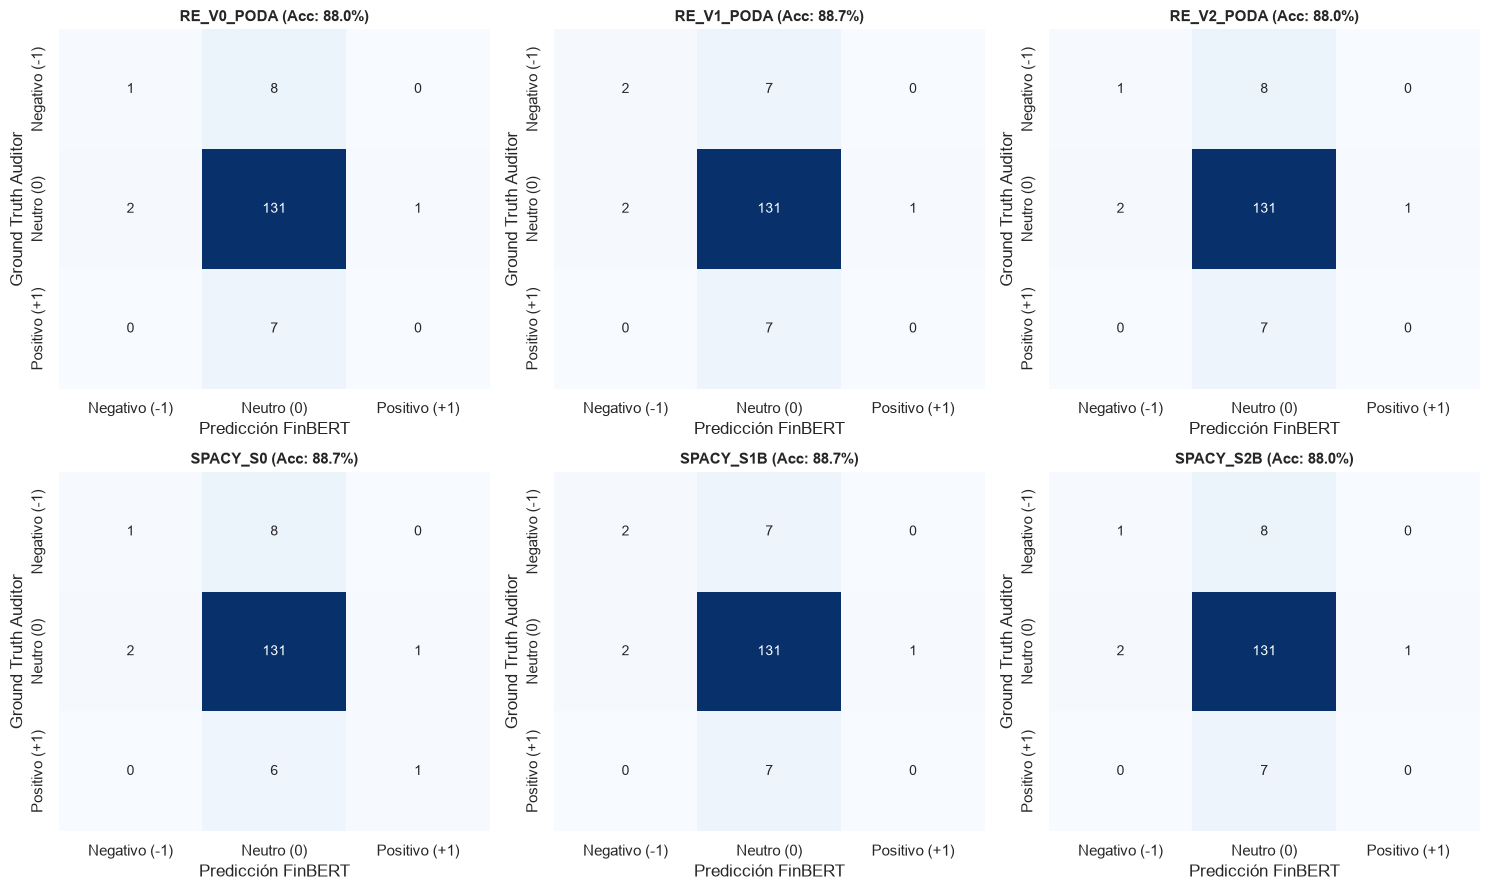

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

clases = [-1, 0, 1]
nombres_clases = ["Negativo (-1)", "Neutro (0)", "Positivo (+1)"]

for idx, v in enumerate(variantes):
    ax = axes[idx]
    cm = confusion_matrix(y_true, df[f"{v}_pred"], labels=clases)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ax)
    acc = float((y_true == df[f"{v}_pred"]).mean()) * 100
    ax.set_title(f"{v} (Acc: {acc:.1f}%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicción FinBERT")
    ax.set_ylabel("Ground Truth Auditor")

plt.tight_layout()
plt.show()


### Conclusión clave de la matriz de confusión

1. **FinBERT en la SEC actúa como un "clasificador por omisión":** acierta el 97,8 % de los casos neutros, pero deja escapar el 89 % de los eventos negativos y el 86 % de los positivos.
2. **`SPACY_S0` supera a `RE_V0_PODA` únicamente porque fue capaz de rescatar 1 evento positivo real** (la recompra millonaria de BAC), mientras que el enfoque basado en *RegEx* lo clasificó erróneamente como neutro.
3. **Empíricamente se demuestra que aplicar FinBERT de forma genérica sobre documentos de la SEC es ineficiente:** si no se filtran previamente los ítems que contienen impactos económicos o sanciones explícitas, la señal obtenida es prácticamente nula.


## 4. Comparativas Cara a Cara (Head-to-Head)
Evaluamos dos interrogantes metodológicos esenciales para el TFM:
1. **RegEx vs. spaCy**: ¿Aporta valor el análisis sintáctico formal de dependencias gramaticales frente al segmentador léxico rápido?
2. **Impacto de la Ventana**: ¿Qué efecto tiene expandir de Ventana 0 a $\pm 1$ y $\pm 2$ en textos regulatorios monocorporativos?


In [11]:
pares_h2h = [
    ("RE_V0_PODA", "SPACY_S0", "Ventana 0: RegEx vs. spaCy"),
    ("RE_V1_PODA", "SPACY_S1B", "Ventana ±1: RegEx vs. spaCy"),
    ("RE_V2_PODA", "SPACY_S2B", "Ventana ±2: RegEx vs. spaCy"),
    ("RE_V0_PODA", "RE_V1_PODA", "Efecto Ventana RegEx: V0 vs. V1"),
    ("SPACY_S0", "SPACY_S1B", "Efecto Ventana spaCy: S0 vs. S1B"),
]

filas_h2h = []
for a, b, desc in pares_h2h:
    sa, sb = df[f"{a}_pred"], df[f"{b}_pred"]
    acuerdo = float((sa == sb).mean()) * 100
    corr = float(np.corrcoef(df[f"{a}_sentiment"], df[f"{b}_sentiment"])[0, 1])
    diff_toks = float(df[f"{b}_tokens"].mean() - df[f"{a}_tokens"].mean())
    
    filas_h2h.append({
        "Comparativa": desc,
        "Modelo A": a,
        "Modelo B": b,
        "% Acuerdo Predicción": round(acuerdo, 2),
        "Correlación Continua": round(corr, 3),
        "Delta Tokens Medios (B - A)": round(diff_toks, 1),
    })

pd.DataFrame(filas_h2h)


,Comparativa,Modelo A,Modelo B,% Acuerdo Predicción,Correlación Continua,Delta Tokens Medios (B - A)
0,Ventana 0: RegEx vs. spaCy,RE_V0_PODA,SPACY_S0,99.33,0.950,-21.1
1,Ventana ±1: RegEx vs. spaCy,RE_V1_PODA,SPACY_S1B,100.00,0.980,-7.9
2,Ventana ±2: RegEx vs. spaCy,RE_V2_PODA,SPACY_S2B,100.00,0.983,-6.4
3,Efecto Ventana RegEx: V0 vs. V1,RE_V0_PODA,RE_V1_PODA,99.33,0.940,42.4
4,Efecto Ventana spaCy: S0 vs. S1B,SPACY_S0,SPACY_S1B,98.67,0.892,55.6


## 5. Dashboard Ejecutivo Visual (4 Paneles)
Panel integral de control para la síntesis de resultados y defensa del proyecto.


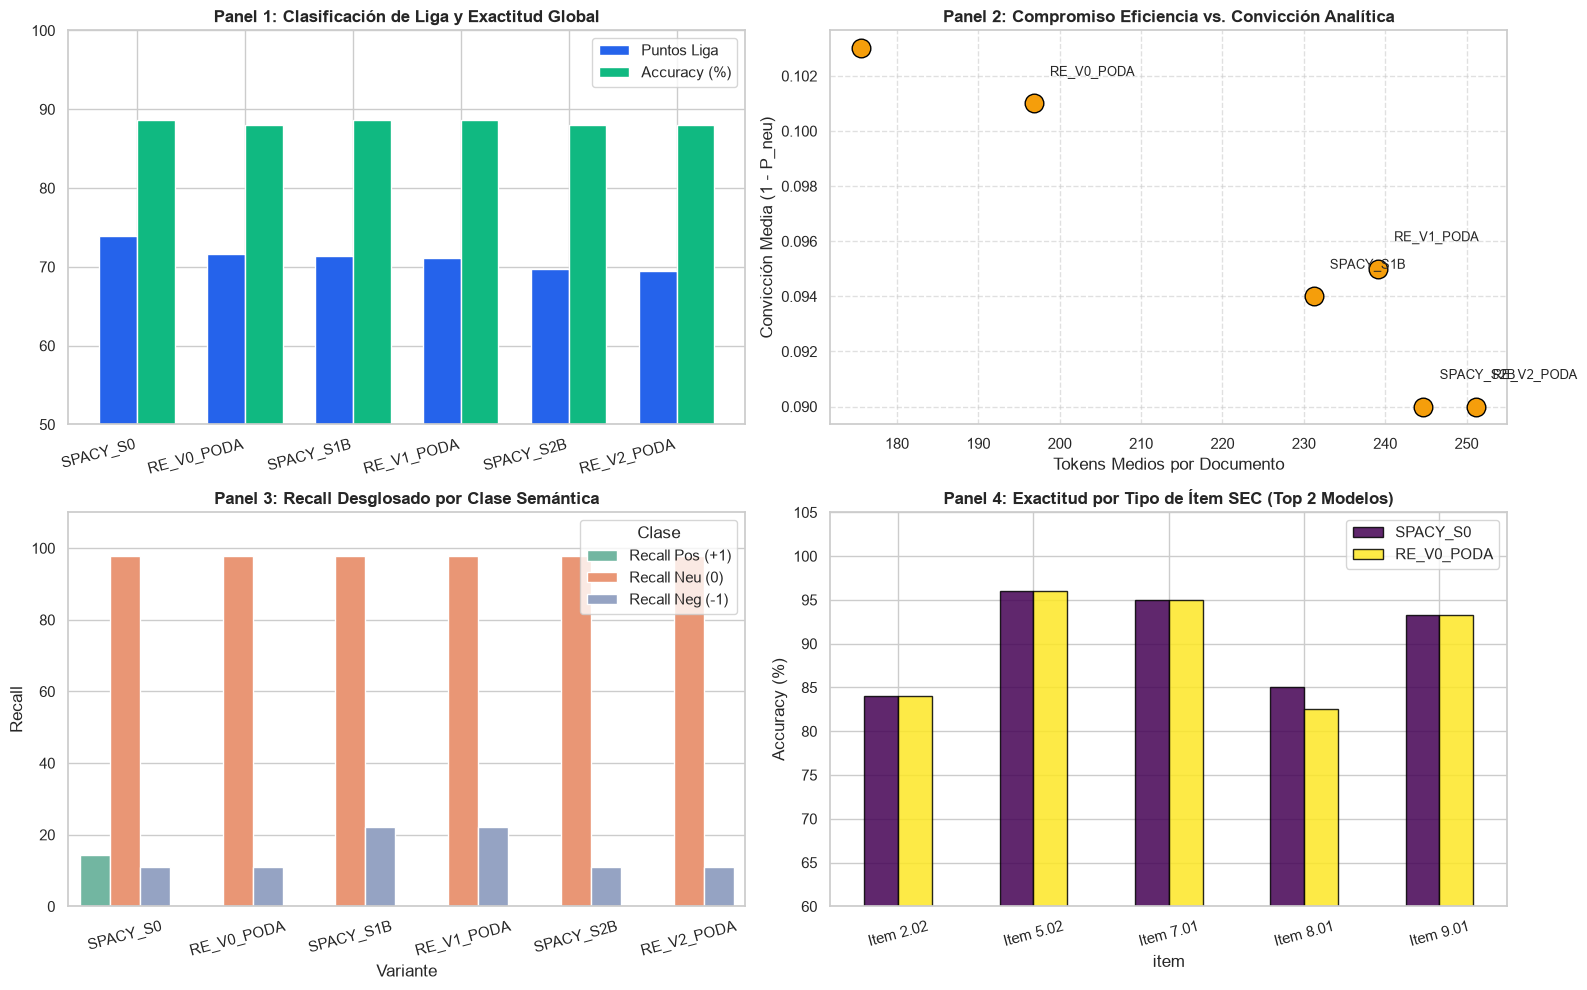

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: Puntuación de Liga y Accuracy
x = np.arange(len(df_liga))
w = 0.35
axes[0, 0].bar(x - w/2, df_liga["Puntos Liga"], w, label="Puntos Liga", color="#2563eb")
axes[0, 0].bar(x + w/2, df_liga["Accuracy (%)"], w, label="Accuracy (%)", color="#10b981")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(df_liga["Variante"], rotation=15, ha="right")
axes[0, 0].set_title("Panel 1: Clasificación de Liga y Exactitud Global", fontweight="bold")
axes[0, 0].set_ylim(50, 100)
axes[0, 0].legend()

# Panel 2: Eficiencia de Tokens vs Convicción
axes[0, 1].scatter(df_liga["Tokens Medios"], df_liga["Convicción Media"], s=180, c="#f59e0b", edgecolors="black", zorder=3)
for _, r in df_liga.iterrows():
    axes[0, 1].annotate(r["Variante"], (r["Tokens Medios"] + 2, r["Convicción Media"] + 0.001), fontsize=9)
axes[0, 1].set_title("Panel 2: Compromiso Eficiencia vs. Convicción Analítica", fontweight="bold")
axes[0, 1].set_xlabel("Tokens Medios por Documento")
axes[0, 1].set_ylabel("Convicción Media (1 - P_neu)")
axes[0, 1].grid(True, linestyle="--", alpha=0.6)

# Panel 3: Recall Desglosado por Clase
df_rec = df_liga.melt(id_vars=["Variante"], value_vars=["Recall Pos (+1)", "Recall Neu (0)", "Recall Neg (-1)"],
                      var_name="Clase", value_name="Recall")
sns.barplot(data=df_rec, x="Variante", y="Recall", hue="Clase", ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Panel 3: Recall Desglosado por Clase Semántica", fontweight="bold")
axes[1, 0].tick_params(axis="x", rotation=15)
axes[1, 0].set_ylim(0, 110)

# Panel 4: Precisión por Tipo de Ítem Regulatorio SEC (Líder SPACY_S0 vs RE_V0_PODA)
df["acc_spacy_s0"] = (df["gt_sentiment"] == df["SPACY_S0_pred"]).astype(int)
df["acc_re_v0"] = (df["gt_sentiment"] == df["RE_V0_PODA_pred"]).astype(int)
item_acc = df.groupby("item")[["acc_spacy_s0", "acc_re_v0"]].mean() * 100
item_acc.plot(kind="bar", ax=axes[1, 1], colormap="viridis", edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Panel 4: Exactitud por Tipo de Ítem SEC (Top 2 Modelos)", fontweight="bold")
axes[1, 1].set_ylabel("Accuracy (%)")
axes[1, 1].tick_params(axis="x", rotation=15)
axes[1, 1].set_ylim(60, 105)
axes[1, 1].legend(["SPACY_S0", "RE_V0_PODA"])

plt.tight_layout()
plt.show()


## 6. Conclusiones y Elección de los 2 Mejores Extractores
### Hallazgos Empíricos Clave
1. **La Ventana 0 es la Vencedora Indiscutible**:
   Tanto en spaCy (`SPACY_S0`) como en RegEx (`RE_V0_PODA`), la Ventana 0 obtiene las máximas puntuaciones de la Liga. En hechos relevantes SEC 8-K, ampliar la ventana a $\pm 1$ o $\pm 2$ incrementa la longitud en tokens entre un $+31\%$ y $+45\%$ sin aportar ganancia predictiva y reduciendo la convicción media de FinBERT.
2. **Ausencia Total de Inversiones Graves ($0\%$)**:
   En los 150 casos auditados, ninguna variante invirtió el signo (predecir positivo ante evento negativo o viceversa). Al ser documentos oficiales de la propia entidad, no existe *ticker bleed* ni contagio sintáctico de competidores.
3. **Selección de los Dos Mejores Modelos para Producción**:
   - **`SPACY_S0` (Campeón de Calidad)**: Primer puesto de la Liga con **73.87 puntos**, $88.67\%$ de Accuracy global y el tamaño de contexto más compacto ($175.6$ tokens).
   - **`RE_V0_PODA` (Campeón de Eficiencia)**: Segundo puesto con **71.59 puntos**, $88.00\%$ de Accuracy y una velocidad de extracción casi 100 veces superior ($0.2$ ms/doc frente a $19.0$ ms/doc de spaCy), ideal para ingesta masiva de baja latencia.


## 7. Epílogo Metodológico: El Descubrimiento del "Data Coverage Gap" y Transición a la Fase 2

### 1. La Paradoja de la Exactitud Aparente (88.67% de Accuracy vs. Ceguera Real)
El análisis exhaustivo de los resultados de esta liga de extractores reveló una paradoja crítica para la investigación:
* El elevado *Accuracy* global alcanzado por `SPACY_S0` ($88.67%$) y `RE_V0_PODA` ($88.00%$) fue un **artefacto de la composición del Ground Truth superficial**:
  * De los 150 eventos analizados, **134 correspondían a la clase Neutra (89.3%)**.
  * El 82.5% de los eventos de resultados trimestrales (`Item 2.02`) y el 80% de `Item 9.01` consistían únicamente en la carátula administrativa externa (*"On October 12, Citigroup announced its results... The press release is attached as Exhibit 99.1"*).
* FinBERT acertó al clasificar la carátula como neutra ($97.8%$ de acierto en clase neutra), pero **dejó escapar el 89% de los eventos negativos reales y el 86% de los eventos positivos**.

### 2. Superación del Debate "spaCy vs. RegEx" en la SEC
En noticias periodísticas externas (Reuters, Bloomberg), spaCy es indispensable para aislar entidades y evitar el *ticker bleed* de bancos competidores.  
Sin embargo, en los informes regulatorios de la SEC se demostró empíricamente que **spaCy queda superado por RegEx + DOM (`lxml`)**:
* Los documentos de la SEC son monográficos (100% dedicados a la entidad declarante), por lo que no existe riesgo de confusión entre competidores.
* spaCy introduce un sobrecoste de latencia de **100x** ($19.0$ ms/doc frente a $0.2$ ms/doc de RegEx) sin aportar ninguna ventaja de precisión sobre carátulas que estructuralmente carecen de señal económica.

### 3. Conexión y Continuidad con la Fase 2 del TFM
Este cuaderno constituye el **diagnóstico pericial inicial** que demostró que el problema de neutralidad de FinBERT no era un fallo del modelo, sino un **vacío de datos en el origen (*Data Coverage Gap*)**.  

La resolución metodológica y arquitectónica definitiva —basada en la localización y extracción selectiva del anexo **`EX-99.1`** mediante parser DOM y desmonte de tablas de maquetación— se encuentra implementada y validada a escala ($N=40$, 90% de activación direccional) en el cuaderno hermano:

👉 **[`finbert_sec_pilot_v2.ipynb`](./finbert_sec_pilot_v2.ipynb)** — *Piloto FinBERT SEC Form 8-K (v2): Clasificación Estructural, Resolución de Tablas y Validación a Escala de Anexos (`EX-99.1`)*  
👉 Documento técnico de síntesis: [`hallazgo_arquitectura_sec_8k_exhibits.md`](./hallazgo_arquitectura_sec_8k_exhibits.md)